### Mouse brain - cell2location paper, Figure 2 (mb01)

**Paper**: Kleshchevnikov V. *et al.* *Comprehensive mapping of tissue cell architecture via integrated single cell and spatial transcriptomics.* bioRxiv 2020.11.15.378125 (published as *Cell2location maps fine-grained cell types in spatial transcriptomics*, Nat Biotechnol 40, 661-671, 2022).

This notebook reproduces the mouse brain panels of **Fig 2** with the classes in `src/libs`:

- `single_cell_lib.SingleCell` - generic Scanpy / Squidpy / cell2location / LIANA methods and `DEFAULT_PARAMS`
- `single_cell_neuro_lib.SingleCellNeuro(SingleCell)` - mouse brain methods and `NEURO_PARAMS`

| section | content | paper |
|---|---|---|
| 1 | open the h5ad files | |
| 2 | components and attributes | |
| 3 | filter data | Methods: genes < 5000, mito < 10% |
| 4 | quality control | Fig S4 |
| 5 | UMAP: broad classes and 59 subtypes | Fig 2B |
| 6 | anatomical regions, major regional subtypes, sparse cell types, fine anatomical subtypes | Fig 2C-F |
| 7 | Slide-seq V2 mapping | Fig 2H |
| 8 | quantitative validation workflow (manually dissected layers) | Fig 2I |
| 9 | heatmap of relative cell subtype proportion per layer | Fig 2J |

**Data** (`mouse_brain/data`): 5 Visium sections (E-MTAB-11114) and snRNA-seq (E-MTAB-11115) from the cell2location server; the paper's own cell2location map with region clusters (sections ST8059048, mouse 1 and ST8059051, mouse 2); squidpy Slide-seqV2; Allen mouse cortex + hippocampus Smart-seq (Yao et al. 2020).

<div class="alert alert-warning">
<b>Differences from the paper</b>

- **Fig 2C-F** use the paper's precomputed cell2location map (2 of the 5 sections); region names come from cell-type enrichment rules (`region_celltype_map`), not from manual annotation.
- **Fig 2H** uses squidpy's Slide-seqV2 hippocampus puck (41,786 beads, 4,000 HVGs, counts recovered from log-normalised X), not the paper's 53,208-bead section; mapping with current cell2location (v0.1.5) priors.
- **Fig 2I/J**: the manual Loupe layer annotation of SSp is not published; cortical layers are taken from the region clusters (all cortex, not SSp only). The Allen taxonomy release gives 104 + 34 cell types (paper: 98 + 23).
- cell2location runs in the sandbox were done on CPU with reduced epochs (tags `cpu3000`, `cpu2000`); rerun with `src/programs/run_c2l_mouse_brain.py --max_epochs 30000 --accelerator gpu` and change the tags below.
</div>

## Loading packages

In [1]:
import os, sys
from pathlib import Path
from importlib.metadata import version
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import anndata as ad
import scanpy as sc

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import rcParams
rcParams['pdf.fonttype'] = 42

ROOT0 = Path('/home/flavio/uv/cell_cell_communication')
ROOT_SRC = ROOT0 / 'src'
if str(ROOT_SRC) not in sys.path:
    sys.path.append(str(ROOT_SRC))

from libs.single_cell_neuro_lib import SingleCellNeuro, NEURO_PARAMS
from libs.matplotlib_figure_style import apply_figure_style
from libs.Basic import pdwritecsv

pd.set_option('display.max_colwidth', 120)
pd.set_option('display.width', 250)
print({p: version(p) for p in ['scanpy', 'squidpy', 'anndata', 'cell2location', 'liana']})

{'scanpy': '1.12.4', 'squidpy': '1.8.3', 'anndata': '0.13.4', 'cell2location': '0.1.5', 'liana': '1.10.0'}


## Parameters

All file names, cutoffs and model settings are set here. `params` overrides `NEURO_PARAMS` / `DEFAULT_PARAMS`; `nr.calc_df_params()` lists every parameter.

In [2]:
project = 'mouse_brain'

# ---- input files (relative to root_data = ROOT0 / project / 'data')
fname_visium     = 'visium_mouse_brain_5sections.h5ad'
fname_snrna      = 'snrna/all_cells_20200625.h5ad'
fname_annot      = 'snrna/snRNA_annotation_astro_subtypes_refined59_20200823.csv'
fname_umap       = 'snrna/mouse_brain_snRNA_with_UMAP_cellxgene.h5ad'
fname_signatures = 'snrna/regression_signatures_sc.h5ad'
fname_map        = 'c2l_paper_map/sp_with_clusters.h5ad'
fname_slideseq   = 'slideseq/slideseqv2.h5ad'
fname_allen      = 'allen_smartseq/allen_smartseq_SSp_PARPOSTPRE.h5ad'

# ---- output files (figures in root_figure, tables in root_result)
fig_qc_visium = 'mb01_qc_visium.png'
fig_qc_snrna  = 'mb01_qc_snrna.png'
fig_2B        = 'mb01_fig2B_umap.png'
fig_2C        = 'mb01_fig2C_regions_{lib}.png'
fig_2DEF      = 'mb01_fig2DEF_density_{lib}.png'
fig_2H        = 'mb01_fig2H_slideseq.png'
fig_2I        = 'mb01_fig2I_layers.png'
fig_2J        = 'mb01_fig2J_layer_heatmap.png'
tsv_regions   = 'mb01_region_clusters.tsv'
tsv_layer     = 'mb01_fig2J_layer_proportions.tsv'

# ---- cutoffs / settings (override NEURO_PARAMS)
params = dict(
    snrna_max_genes=5000,          # paper: genes per nucleus < 5000
    snrna_max_mt_frac=0.10,        # paper: mitochondrial fraction < 0.10
    density_quantile=0.992,        # colour cap of density panels
    region_label_override={'11': 'CTX_L1', '21': 'edge_LowQ'},   # justified in section 6 (edge fraction)
    accelerator='auto',            # 'gpu' on a CUDA machine
)
library_main = 'ST8059048'         # section shown in Fig 2C-F, 2I (mouse 1); the other mapped one is ST8059051

# ---- cell2location runs (cached by src/programs/run_c2l_mouse_brain.py)
c2l_tag_slideseq     = 'cpu2000'   # results/c2l_slideseq_<tag>
c2l_tag_allen        = 'cpu3000'   # results/c2l_allen_ssp_<tag>
c2l_train_if_missing = False       # True -> train here when the cache is missing (GPU recommended)
c2l_max_epochs       = 30000       # paper: 30000

apply_figure_style()
nr = SingleCellNeuro(ROOT0, project, params=params)
root_data, root_figure, root_result = nr.root_data, nr.root_figure, nr.root_result
print(nr)
print(root_data, '\n', sorted(os.listdir(root_data)))

SingleCellNeuro(project='mouse_brain', adata=None, symbol_col='SYMBOL', sample_col='sample')
/home/flavio/uv/cell_cell_communication/mouse_brain/data 
 ['allen_smartseq', 'c2l_paper_map', 'inspect.txt', 'mouse_brain_visium_wo_cloupe_data', 'mouse_brain_visium_wo_cloupe_data.zip', 'slideseq', 'snrna', 'visium_hne.h5ad', 'visium_hne_liana_bivariate.h5ad', 'visium_mouse_brain_5sections.h5ad']


In [3]:
df_params = nr.calc_df_params()
df_params[df_params.value.astype(str) != df_params.default.astype(str)]

,parameter,value,default
77,region_label_override,"{'11': 'CTX_L1', '21': 'edge_LowQ'}",{}


## 1. Open the h5ad files

- **adata_vis**: 5 Visium sections merged (`download_mouse_brain_visium.py`), Ensembl `var_names`, symbols in `var['SYMBOL']`
- **adata_ref**: snRNA-seq raw counts, 6 samples (5 paired with Visium + 1 extra section)

In [4]:
adata_vis = nr.read_h5ad(fname_visium, set_self=False)
adata_ref = nr.read_h5ad(fname_snrna, set_self=False)
adata_vis, adata_ref

(AnnData object with n_obs × n_vars = 14968 × 31053
     obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'sample_name2', 'image_name', 'slide', 'position'
     var: 'SYMBOL', 'MT_gene'
     uns: 'spatial'
     obsm: 'spatial'
     layers: None (.X),
 AnnData object with n_obs × n_vars = 40572 × 31053
     obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'mt_frac', 'sample', 'barcode'
     var: 'feature_types', 'genome', 'SYMBOL', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'mt'
     layers: None (.X))

## 2. Components and attributes

In [5]:
nr.summary(adata_vis)

AnnData object with n_obs × n_vars = 14968 × 31053
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'sample_name2', 'image_name', 'slide', 'position'
    var: 'SYMBOL', 'MT_gene'
    uns: 'spatial'
    obsm: 'spatial'
    layers: None (.X)

X: {'type': 'csr_matrix', 'dtype': 'float32', 'shape': (14968, 31053), 'density': 0.1456, 'min': 1.0, 'max': 5308.0, 'integer': True, 'nnz_per_row': 4520.1}

obs columns (8): ['in_tissue', 'array_row', 'array_col', 'sample', 'sample_name2', 'image_name', 'slide', 'position']
var columns (2): ['SYMBOL', 'MT_gene']
obsm: {'spatial': (14968, 2)}
layers: [None]
uns: ['spatial']
  library ST8059048: images [('hires', (2000, 1969, 3)), ('lowres', (600, 591, 3))]
  library ST8059049: images [('hires', (2000, 1969, 3)), ('lowres', (600, 591, 3))]
  library ST8059050: images [('hires', (2000, 1968, 3)), ('lowres', (600, 590, 3))]
  library ST8059051: images [('hires', (2000, 1963, 3)), ('lowres', (600, 589, 3))]
  library ST8059052: images [('hires'

In [6]:
df_comp_vis = nr.calc_df_components(adata_vis)
df_comp_vis.groupby('slot').size().to_frame('n_keys').T

slot,X,layers,obs,obsm,uns,var
n_keys,1,1,8,1,1,2


In [7]:
df_sections = adata_vis.obs.groupby(nr.sample_col, observed=True).agg(
    n_spots=('in_tissue', 'size'), in_tissue=('in_tissue', 'sum'))
df_sections['slide'] = [s for s in df_sections.index]
df_sections['image_hires'] = [adata_vis.uns['spatial'][s]['images']['hires'].shape for s in df_sections.index]
df_sections

,n_spots,in_tissue,slide,image_hires
sample,,,,
ST8059048,2987,2987,ST8059048,"(2000, 1969, 3)"
ST8059049,3499,3499,ST8059049,"(2000, 1969, 3)"
ST8059050,3497,3497,ST8059050,"(2000, 1968, 3)"
ST8059051,2409,2409,ST8059051,"(2000, 1963, 3)"
ST8059052,2576,2576,ST8059052,"(2000, 1950, 3)"


In [8]:
nr.summary(adata_ref)

AnnData object with n_obs × n_vars = 40572 × 31053
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'mt_frac', 'sample', 'barcode'
    var: 'feature_types', 'genome', 'SYMBOL', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'mt'
    layers: None (.X)

X: {'type': 'csr_matrix', 'dtype': 'float32', 'shape': (40572, 31053), 'density': 0.0819, 'min': 1.0, 'max': 3631.0, 'integer': True, 'nnz_per_row': 2542.5}

obs columns (11): ['n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'mt_frac', 'sample', 'barcode']
var columns (10): ['feature_types', 'genome', 'SYMBOL', 'n_cells_by_counts', 'mean_count

In [9]:
df_samples_ref = adata_ref.obs[nr.sample_col].value_counts().to_frame('n_nuclei')
df_samples_ref

,n_nuclei
sample,
5705STDY8058285,10260
5705STDY8058281,8253
5705STDY8058280,8150
5705STDY8058282,5799
5705STDY8058283,5215
5705STDY8058284,2895


## 3. Filter data

**snRNA-seq** (paper Methods): nuclei with < 5000 detected genes and mitochondrial fraction < 0.10 are kept. The paper's annotation then defines the 40,532 nuclei used as reference.

No doublet filter is applied: the annotated nuclei are already the post-scrublet set of the paper, and Visium spots contain several cells by design, so doublet scores do not apply to the spatial data.

In [10]:
adata_ref, df_filter_ref = nr.filter_snrna(adata_ref, inplace=False)
print(f"kept {df_filter_ref.attrs['kept']:,} of {df_filter_ref.attrs['total']:,} nuclei")
df_filter_ref

kept 40,570 of 40,572 nuclei


,criterion,threshold,failing,removed_here
0,n_genes_by_counts < max_genes,5000.0,2,2
1,pct_counts_mt < max_pct_mt,10.0,0,0


In [11]:
adata_ref, df_annot = nr.add_paper_annotation(fname_annot, adata_ref)
print(f"annotation: {len(df_annot):,} nuclei, {df_annot[nr.params['celltype_col']].nunique()} cell types; "
      f"after QC + annotation: {adata_ref.n_obs:,}")
adata_ref.obs[nr.params['broad_col']].value_counts().to_frame('n_nuclei').T

annotation: 40,532 nuclei, 59 cell types; after QC + annotation: 40,530


broad_class,Excitatory,Oligo_OPC,Inhibitory,Astrocytes,Other,Micro,Endo
n_nuclei,13013,12747,8470,3013,2047,1218,22


**Visium**: spots under tissue only; mitochondrial genes removed for mapping (their counts kept in `obsm['MT']`); genes shared with the reference signatures (paper: 12,809 genes, 14,968 locations).

In [12]:
adata_vis = adata_vis[adata_vis.obs['in_tissue'] == 1].copy()
n_genes0 = adata_vis.n_vars
adata_vis = nr.remove_mt_genes(adata_vis)
df_sig_ref = nr.signatures_from_regression(fname_signatures, use_symbols=False)
n_shared = len(np.intersect1d(adata_vis.var_names, df_sig_ref.index))
print(f"Visium: {adata_vis.n_obs:,} spots; genes {n_genes0:,} -> {adata_vis.n_vars:,} without MT; "
      f"shared with the 59 signatures: {n_shared:,}")

Visium: 14,968 spots; genes 31,053 -> 31,040 without MT; shared with the 59 signatures: 12,809


## 4. Quality control

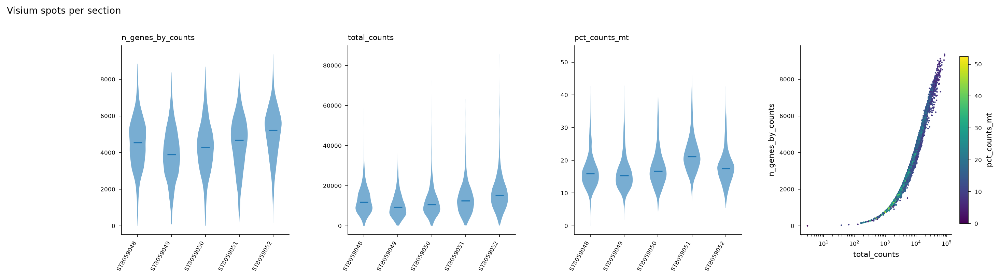

,n,median_n_genes_by_counts,median_total_counts,median_pct_counts_mt,q25_n_genes_by_counts,q25_total_counts,q25_pct_counts_mt,q75_n_genes_by_counts,q75_total_counts,q75_pct_counts_mt
sample,,,,,,,,,,
ST8059048,2987,4541.0,11736.0,15.930000,3537.00,7968.00,13.28,5463.50,16634.5,18.92
ST8059049,3499,3885.0,9206.0,15.300000,2946.50,5838.00,12.65,4877.00,13605.5,18.39
ST8059050,3497,4281.0,10589.0,16.740000,3327.00,7069.00,13.89,5166.00,14978.0,20.31
ST8059051,2409,4669.0,12543.0,21.200001,3567.00,8145.00,18.26,5563.00,17415.0,24.90
ST8059052,2576,5215.5,15209.5,17.559999,4165.25,10570.75,14.72,6003.25,20370.0,20.55


In [13]:
nr.calc_qc_metrics(adata_vis)
# MT genes were removed in section 3; their counts are in obsm['MT'] -> mito % of all counts
mt_counts = np.asarray(adata_vis.obsm['MT']).sum(1)
adata_vis.obs['pct_counts_mt'] = 100 * mt_counts / (adata_vis.obs['total_counts'].values + mt_counts)
fig = nr.plot_qc(adata=adata_vis, fname=fig_qc_visium, title='Visium spots per section')
plt.show()
nr.calc_df_qc(adata=adata_vis)

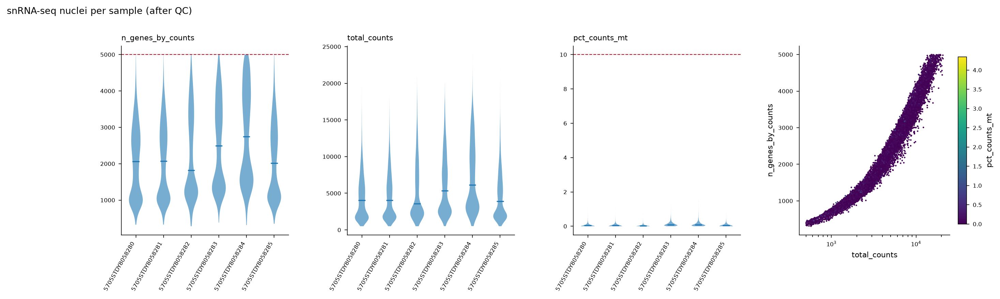

,n,median_n_genes_by_counts,median_total_counts,median_pct_counts_mt,q25_n_genes_by_counts,q25_total_counts,q25_pct_counts_mt,q75_n_genes_by_counts,q75_total_counts,q75_pct_counts_mt
sample,,,,,,,,,,
5705STDY8058280,8147,2060.0,4031.0,0.04,1111.00,1875.00,0.00,2831.0,6527.00,0.08
5705STDY8058281,8250,2070.0,4062.5,0.04,1121.00,1894.25,0.00,2921.0,6772.00,0.08
5705STDY8058282,5789,1820.0,3602.0,0.02,1215.00,2204.00,0.00,3304.0,8099.00,0.05
5705STDY8058283,5212,2497.5,5344.0,0.08,1414.00,2613.00,0.04,3570.0,9048.00,0.16
5705STDY8058284,2890,2747.5,6145.5,0.08,1605.25,3196.00,0.03,3920.5,10799.25,0.15
5705STDY8058285,10242,2012.5,3928.5,0.05,1147.25,1972.00,0.01,2908.0,6746.25,0.09


In [14]:
fig = nr.plot_qc(adata=adata_ref, fname=fig_qc_snrna, title='snRNA-seq nuclei per sample (after QC)',
                 thresholds={'n_genes_by_counts': nr.params['snrna_max_genes'],
                             'pct_counts_mt': 100 * nr.params['snrna_max_mt_frac']})
plt.show()
nr.calc_df_qc(adata=adata_ref)

In [15]:
df_ct_sample = pd.crosstab(adata_ref.obs[nr.params['celltype_col']], adata_ref.obs[nr.sample_col])
print("cell types present in all 6 samples:", int((df_ct_sample > 0).all(1).sum()), "of", len(df_ct_sample))
df_ct_sample.head(10)

cell types present in all 6 samples: 53 of 59


sample,5705STDY8058280,5705STDY8058281,5705STDY8058282,5705STDY8058283,5705STDY8058284,5705STDY8058285
annotation_1,,,,,,
Astro_AMY,36,89,63,89,64,157
Astro_AMY_CTX,76,92,41,24,7,39
Astro_CTX,110,98,25,60,33,117
Astro_HPC,48,53,29,24,24,83
Astro_HYPO,91,88,53,72,61,86
Astro_STR,2,8,0,28,12,31
Astro_THAL_hab,6,5,17,5,2,8
Astro_THAL_lat,69,54,45,34,23,107
Astro_THAL_med,82,67,94,41,32,89


## 5. UMAP - broad classes and 59 subtypes (Fig 2B)

The UMAP coordinates, `annotation_1` and `broad_class` are the paper's (cellxgene object); only obs and obsm are read.

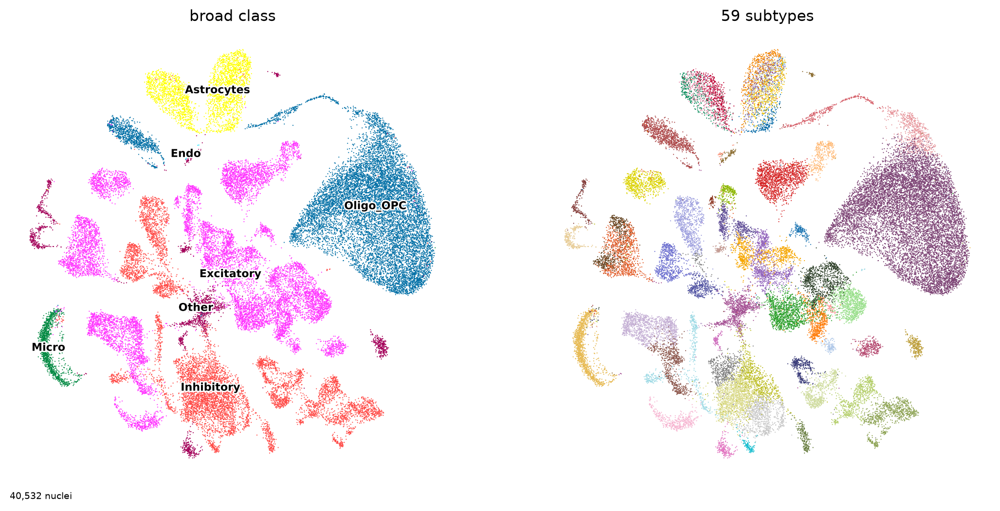

broad_class,Excitatory,Oligo_OPC,Inhibitory,Astrocytes,Other,Micro,Endo
n_nuclei,13014,12747,8471,3013,2047,1218,22


In [16]:
adata_umap = nr.load_umap_obs(fname_umap)
fig = nr.plot_umap_broad_subtypes(adata_umap, fname=fig_2B)
plt.show()
adata_umap.obs[nr.params['broad_col']].value_counts().to_frame('n_nuclei').T

## 6. Anatomical regions, major regional subtypes, sparse cell types, fine anatomical subtypes (Fig 2C-F)

The paper's cell2location map gives cells per spot (`q05_spot_factors<type>`, 59 types) and `region_cluster` (Leiden on abundance; paper Methods: kNN 38, resolution 1.3).

Each region cluster is named by the cell types most enriched in it (cluster mean / slide mean), using `region_celltype_map`.

In [17]:
adata_map = nr.load_paper_map(fname_map)
df_abund = nr.calc_df_abundance(adata_map)
print(adata_map.shape, nr.library_ids(adata_map), df_abund.shape)
df_regions = nr.calc_df_regions(adata_map)
df_regions

(5396, 31040) ['ST8059048', 'ST8059051'] (5396, 59)


,region_cluster,n_spots,label,top_types,top_enrich,label_votes
0,0,421,WM,Oligo_2 / OPC_2 / Astro_WM,6.0 / 5.6 / 5.0,WM:15.1
1,1,365,CTX_L5,Ext_L5_2 / LowQ_2 / Ext_Med,12.1 / 9.7 / 6.6,CTX_L5:16.8; HAB:6.6
2,2,358,CTX_L5/6,Ext_L56 / Ext_ClauPyr / Ext_L6,11.0 / 10.5 / 8.3,CTX_L5/6:11.0; CLA:10.5; CTX_L6:8.3
3,3,327,CTX_L2/3,Ext_L23 / Inh_Vip / Ext_Med,12.4 / 4.4 / 3.6,CTX_L2/3:12.4; HAB:3.6; CTX_L4:3.4
4,4,296,AMY,Ext_Amy_2 / Inh_Sst / Inh_Vip,14.1 / 4.1 / 3.1,AMY:16.6; STR:2.3
5,5,294,THAL,Ext_Thal_2 / Ext_Unk_3 / Astro_THAL_med,14.8 / 11.1 / 6.6,THAL:24.5
6,6,289,STR,Inh_Meis2_2 / Inh_Meis2_3 / Astro_STR,16.9 / 16.5 / 4.4,STR:37.8
7,7,279,PIR,Ext_Pir / Astro_AMY_CTX / Ext_Unk_1,14.5 / 2.3 / 2.0,PIR:14.5; AMY:1.6
8,8,258,STR,Inh_1 / Inh_Meis2_1 / Inh_4,14.5 / 13.1 / 5.9,STR:13.1; AMY:4.2; HYPO:3.9
9,9,231,THAL,Ext_Thal_1 / Astro_THAL_lat / Astro_THAL_med,8.1 / 5.6 / 5.0,THAL:18.7


**Edge check.** Two clusters are not labelled well by enrichment alone. A Visium spot has 6 neighbours; spots on the tissue border have fewer. Cluster 11 (Inh_Lamp5, Astro enriched) lies on the pial surface: it is **cortical layer 1**. Cluster 21 (LowQ_1) is a tissue-rim artefact. Both are set with `region_label_override`.

In [18]:
df_edge = nr.calc_df_edge_fraction(adata_map)
df_regions_edge = df_regions.set_index('region_cluster').join(df_edge)
df_regions_edge.loc[df_regions_edge.mean_frac_edge > 0.25, ['label', 'top_types', 'mean_frac_edge']]

,label,top_types,mean_frac_edge
region_cluster,,,
11,HPC,Astro_HPC / Astro_AMY_CTX / Inh_Lamp5,0.638
12,HPC_DG,Ext_Hpc_DG1 / Ext_Hpc_DG2 / Nb_1,0.312
21,WM,LowQ_1 / Astro_WM / Endo,0.781
26,HAB,Inh_6 / Astro_THAL_hab / Astro_WM,0.421


In [19]:
nr.add_region_labels(df_regions, adata_map)
df_regions['label_final'] = df_regions.region_cluster.map(lambda c: nr.params['region_label_override'].get(c))
df_regions['label_final'] = df_regions['label_final'].fillna(df_regions['label'])
pdwritecsv(df_regions.join(df_edge[['mean_frac_edge']], on='region_cluster'), tsv_regions, root_result)
adata_map.obs['region_label'].value_counts().to_frame('n_spots').T

region_label,THAL,STR,CTX_L5,WM,HYPO,HAB,CTX_L5/6,AMY,CTX_L2/3,PIR,CTX_L1,HPC_DG,CTX_L6b,CTX_L4,HPC_CA3,edge_LowQ,HPC_CA1
n_spots,796,622,496,421,384,360,358,338,327,279,210,202,144,143,129,119,68


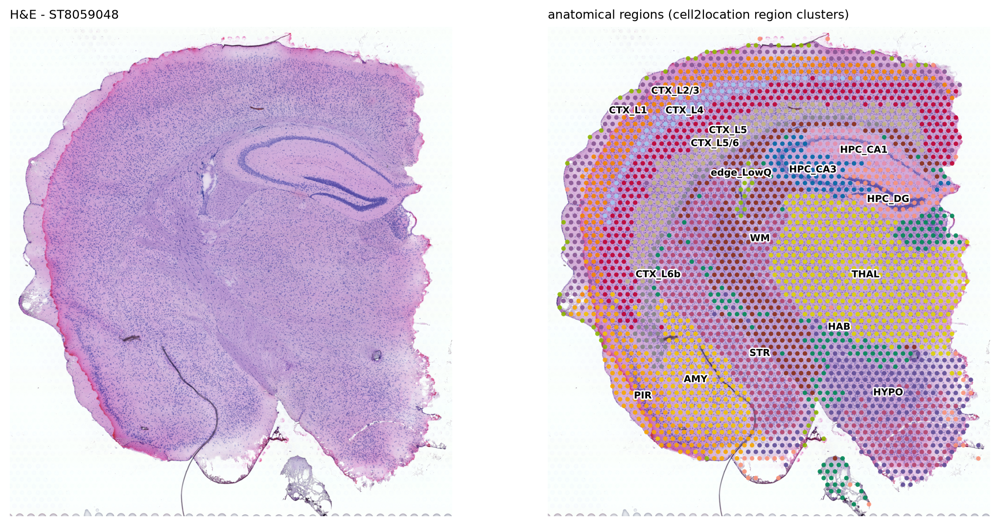

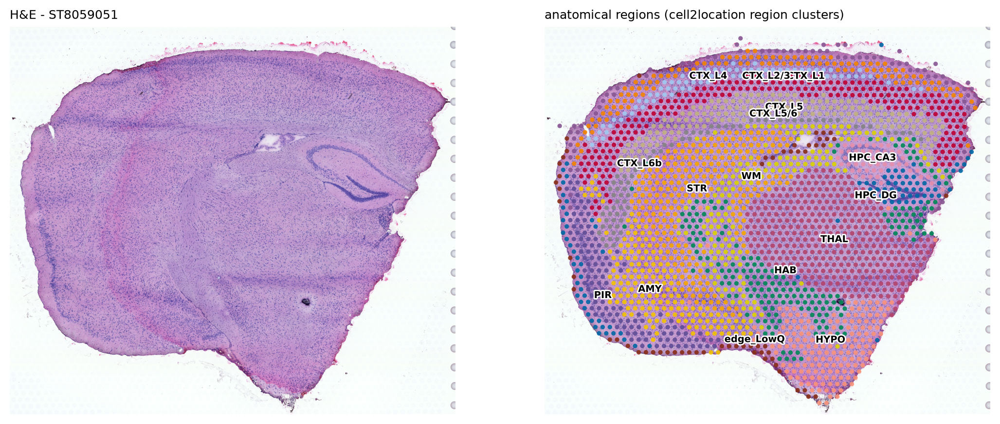

In [20]:
for lib in nr.library_ids(adata_map):
    fig = nr.plot_regions_he(adata_map, library_id=lib, fname=fig_2C.format(lib=lib))
    plt.show()

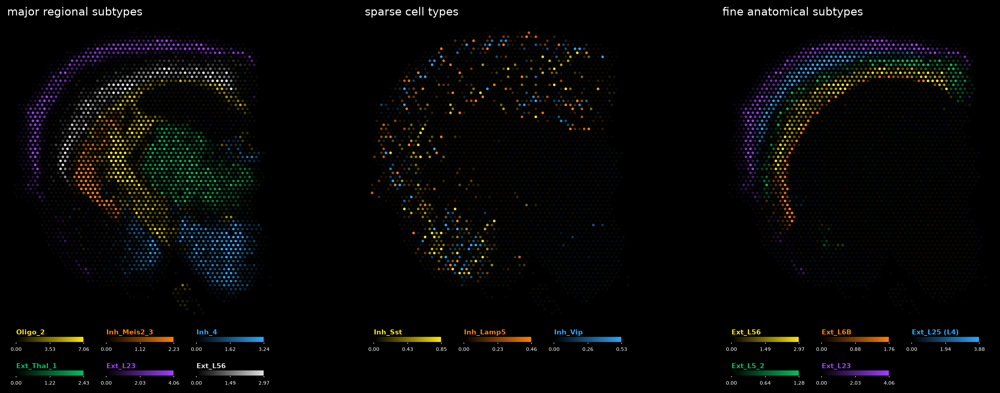

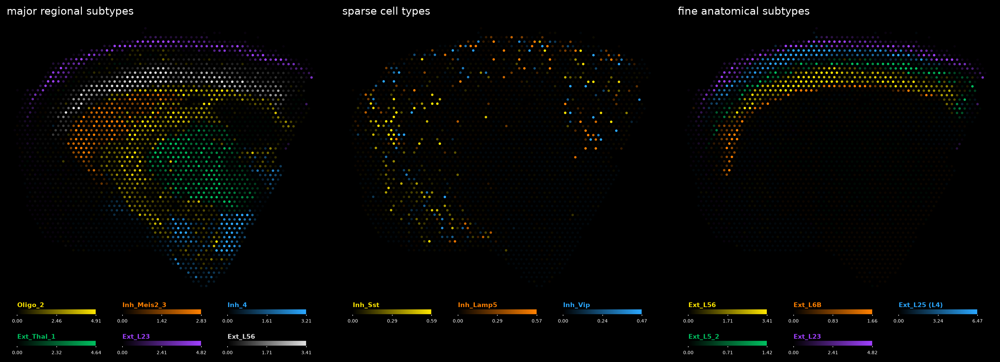

,panel,cell_type,cap_cells_per_spot
0,major regional subtypes,Oligo_2,4.914
1,major regional subtypes,Inh_Meis2_3,2.833
2,major regional subtypes,Inh_4,3.211
3,major regional subtypes,Ext_Thal_1,4.643
4,major regional subtypes,Ext_L23,4.824
5,major regional subtypes,Ext_L56,3.410
6,sparse cell types,Inh_Sst,0.588
7,sparse cell types,Inh_Lamp5,0.571
8,sparse cell types,Inh_Vip,0.472
9,fine anatomical subtypes,Ext_L56,3.410


In [21]:
panels = {'major regional subtypes': nr.params['fig2D_types'],
          'sparse cell types': nr.params['fig2E_types'],
          'fine anatomical subtypes': nr.params['fig2F_types']}
for lib in nr.library_ids(adata_map):
    fig = nr.plot_density_panels(panels, adata_map, library_id=lib, df_abund=df_abund, fname=fig_2DEF.format(lib=lib))
    plt.show()
fig.df_caps

Colour scale per cell type: 0 to the 99.2% quantile of cells per spot. `Ext_L25` (L2-5 IT neurons, peak in L4) is shown as **Ext_L25 (L4)**: the 59-type annotation has no `Ext_L4`, the label used in Fig 2F.

## 7. Slide-seq V2 (Fig 2H)

The 59 snRNA signatures (paper NB regression) are mapped to a Slide-seqV2 puck of the mouse hippocampus (Stickels et al. 2021). Paper priors for 10-µm beads: 1 cell and 1 cell type per location.

squidpy stores `X = log1p(normalize_total)` on 4,000 HVGs with the raw library size in `obs['total_counts']`; counts are recovered exactly as `expm1(X) * total_counts / target`.

In [22]:
adata_ss, df_sig_ss, diag_ss = nr.prepare_slideseq_mapping(fname_slideseq, fname_signatures)
print(adata_ss.shape, diag_ss)

(41786, 4000) {'target_sum': 432.00001287460327, 'max_err': 0.49910529947726445, 'frac_values_err_gt_tol': 0.00018002767528721103, 'median_err': 1.0321363177467902e-06, 'n_genes_shared': 2528}


In [23]:
run_dir_ss = root_result / f'c2l_slideseq_{c2l_tag_slideseq}'
if (run_dir_ss / 'sp.h5ad').exists() or c2l_train_if_missing:
    adata_ss_map = nr.train_mapping(adata_ss, df_sig_ss, run_dir_ss, N_cells_per_location=nr.params['slideseq_N'],
                                    detection_alpha=nr.params['slideseq_alpha'], max_epochs=c2l_max_epochs,
                                    A_factors_per_location=nr.params['slideseq_A'],
                                    B_groups_per_location=nr.params['slideseq_B'])
    print(adata_ss_map.shape, {k: v for k, v in adata_ss_map.uns['c2l_training'].items() if k != 'elbo_history'})
else:
    adata_ss_map = None
    print(f"no cached run in {run_dir_ss}: run src/programs/run_c2l_mouse_brain.py --mode slideseq")

(41786, 2528) {'N_cells_per_location': 1, 'accelerator': 'auto', 'detection_alpha': 20, 'max_epochs': 2000, 'n_genes': 2528}


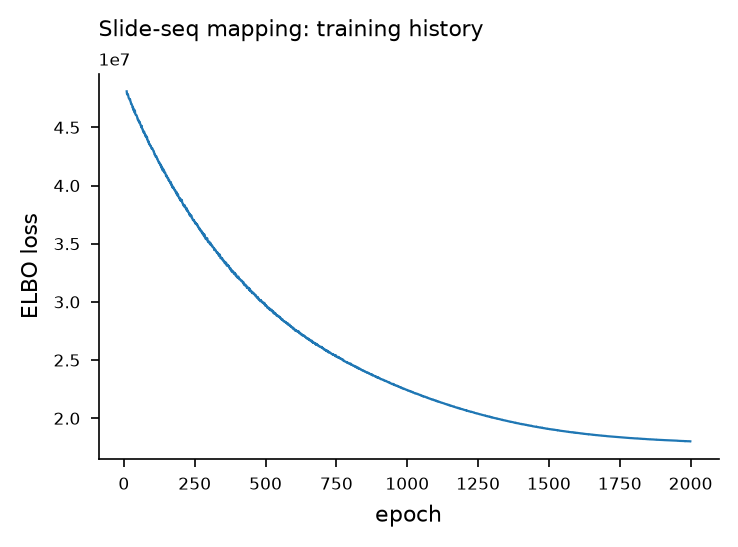

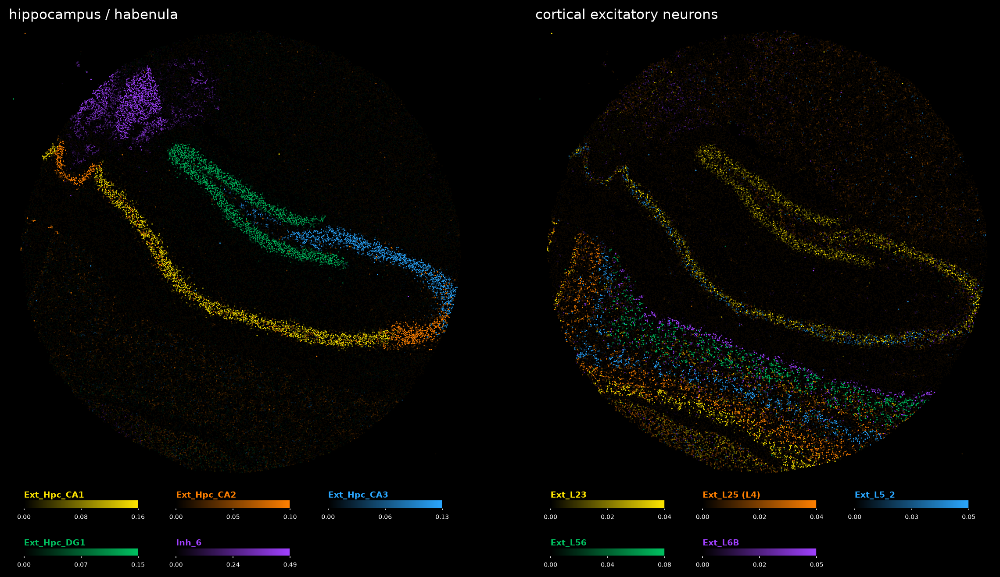

In [24]:
if adata_ss_map is not None:
    elbo = np.asarray(adata_ss_map.uns['c2l_training']['elbo_history'])
    fig, ax = plt.subplots(figsize=(4, 2.5))
    ax.plot(np.arange(len(elbo))[10:], elbo[10:], lw=0.8)
    ax.set_xlabel('epoch'); ax.set_ylabel('ELBO loss'); ax.set_title('Slide-seq mapping: training history')
    plt.show()
    fig = nr.plot_slideseq(adata_ss_map, fname=fig_2H)
    plt.show()

## 8. Quantitative validation workflow based on scRNA-seq from manually dissected layers (Fig 2I)

Allen Smart-seq cells from the primary somatosensory cortex (SSp) were dissected by layer (Yao et al. 2020). Following the paper:

- cell types of SSp plus types exclusive to the hippocampal subiculum (PAR-POST-PRE), with ≥ 3 cells
- signatures = per-cluster average expression (NB regression is not suited to Smart-seq)
- mapped with cell2location to the Visium cortical-layer spots (here: region clusters CTX_L1 ... CTX_L6b)

In [25]:
adata_allen = nr.read_h5ad(fname_allen, set_self=False)
nr.sanitize_allen_types(adata_allen)          # '166_L2/3 IT CTX' -> '166_L2-3 IT CTX' ('/' is not allowed in h5ad keys)
df_meta_allen = adata_allen.obs
df_type_counts, types_ssp, types_hpc = nr.allen_select_types(df_meta_allen)
print(f"Allen cells: {adata_allen.n_obs:,} ({df_meta_allen[nr.params['allen_region_col']].value_counts().to_dict()}); "
      f"types: SSp {len(types_ssp)} + hippocampus-exclusive {len(types_hpc)} = {len(types_ssp) + len(types_hpc)}")
df_allen_counts, df_allen_prop = nr.calc_df_allen_layer_prop(df_meta_allen, types_ssp)
df_allen_counts.sum().to_frame('cells per layer (SSp)').T

Allen cells: 7,249 ({'SSp': 5665, 'PAR-POST-PRE': 1584}); types: SSp 104 + hippocampus-exclusive 34 = 138


_layer,L1,L2/3,L4,L5,L6
cells per layer (SSp),32,1183,992,741,2157


{'L1': 210, 'L2/3': 327, 'L4': 143, 'L5': 496, 'L6': 502}


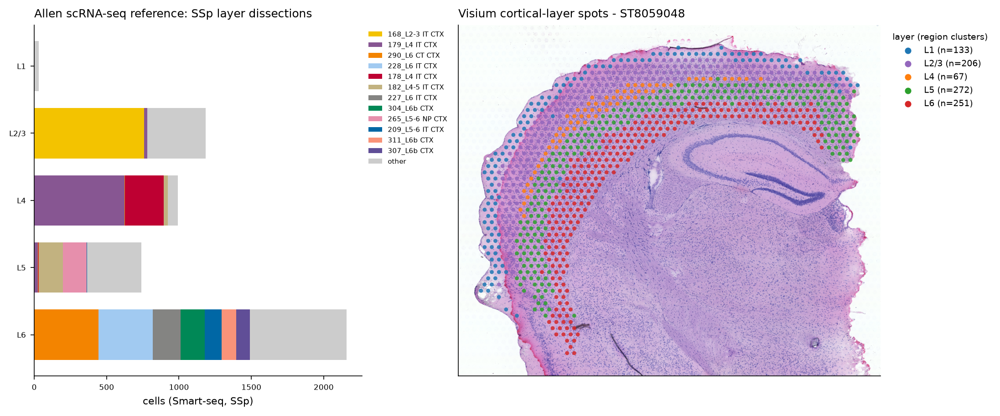

In [26]:
nr.assign_cortical_layers(adata_map)
print(adata_map.obs['cortical_layer'].value_counts().reindex(list(nr.params['layers'])).to_dict())
fig = nr.plot_layer_workflow(adata_map, library_id=library_main, df_allen_counts=df_allen_counts, fname=fig_2I)
plt.show()

## 9. Heatmap of relative cell subtype proportion (Fig 2J)

Proportion of each cell type within each layer: Allen = cell counts of the SSp layer dissections; cell2location = mean estimated density per layer, normalised over all mapped types. Shown are the 23 most prevalent SSp-exclusive types (count in SSp > 15, absent from the hippocampal region).

{'n_types_ssp': 104, 'n_types_hpc': 34, 'n_genes_filtered': 34297, 'n_spots': 1678, 'n_genes_shared': 19884}
(1678, 19884) {'N_cells_per_location': 8, 'accelerator': 'cpu', 'detection_alpha': 20, 'max_epochs': 3000, 'n_genes': 19884, 'note': 'posterior exported from the saved model'}


  result = getattr(ufunc, method)(*inputs, **kwargs)

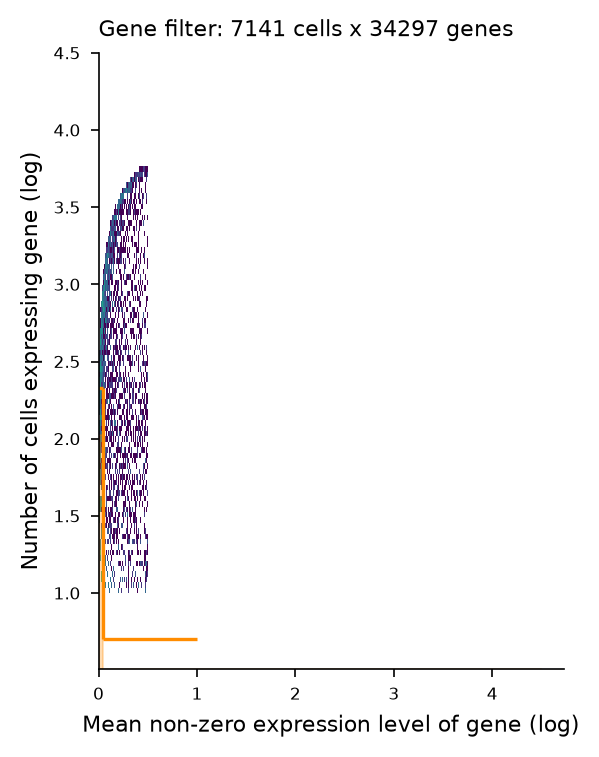

In [27]:
run_dir_allen = root_result / f'c2l_allen_ssp_{c2l_tag_allen}'
if (run_dir_allen / 'sp.h5ad').exists() or c2l_train_if_missing:
    adata_ctx, df_sig_allen, info_allen = nr.prepare_allen_mapping(adata_allen, adata_map)
    print({k: v for k, v in info_allen.items() if k not in ('types', 'df_type_counts')})
    adata_allen_map = nr.train_mapping(adata_ctx, df_sig_allen, run_dir_allen, N_cells_per_location=nr.params['c2l_allen_N'],
                                       detection_alpha=nr.params['c2l_allen_alpha'], max_epochs=c2l_max_epochs,
                                       batch_key=nr.sample_col, A_factors_per_location=nr.params['c2l_allen_A'])
    # layers from the current region labels (the cached obs may predate a change of layer_from_region)
    adata_allen_map.obs['cortical_layer'] = adata_map.obs.loc[adata_allen_map.obs_names, 'cortical_layer'].values
    print(adata_allen_map.shape, {k: v for k, v in adata_allen_map.uns['c2l_training'].items() if k != 'elbo_history'})
else:
    adata_allen_map = None
    print(f"no cached run in {run_dir_allen}: run src/programs/run_c2l_mouse_brain.py --mode allen")

{'R2_linear': np.float64(0.8111350561058089), 'R2_log10': np.float64(0.5472576567269589), 'n_cells_compared': 115}


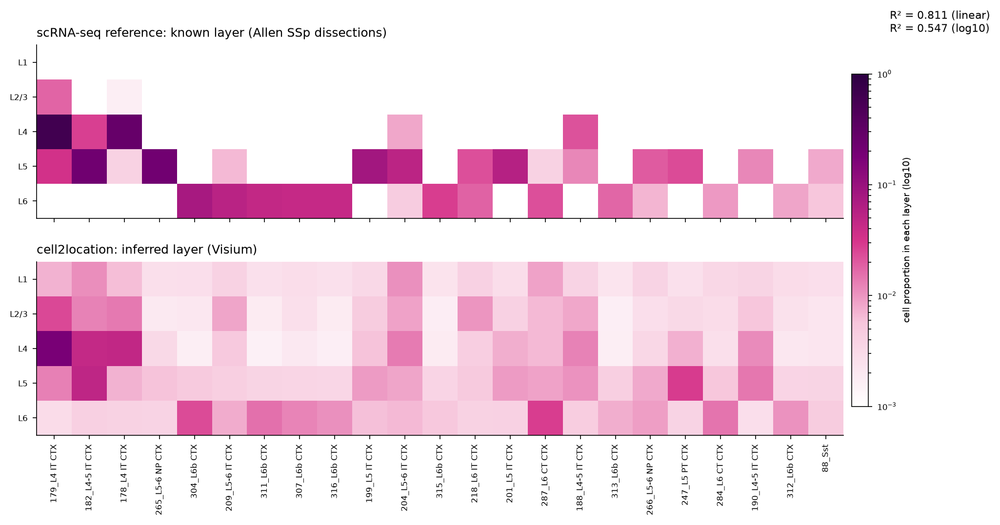

In [28]:
if adata_allen_map is not None:
    types_top = nr.allen_top_types(df_type_counts)
    df_c2l_prop = nr.calc_df_c2l_layer_prop(adata_allen_map, nr.calc_df_abundance(adata_allen_map).columns)
    fig, stats_2J = nr.plot_layer_heatmaps(df_allen_prop, df_c2l_prop, types_top, fname=fig_2J)
    plt.show()
    print(stats_2J)
    df_layer_prop = pd.concat({'allen': df_allen_prop.reindex(types_top), 'cell2location': df_c2l_prop.reindex(types_top)}, axis=1)
    df_layer_prop.columns = [f'{a}_{l}' for a, l in df_layer_prop.columns]
    pdwritecsv(df_layer_prop.round(5).reset_index(names='cell_type'), tsv_layer, root_result)
    df_layer_prop.round(3)

### Notes for interpretation

- Fig 2C-F come from the paper's own cell2location run; region names are rule-based (`region_celltype_map`, `region_label_override`) and can be edited in `params`.
- Fig 2H and 2J are new cell2location runs. The cached CPU runs use fewer epochs than the paper (30,000), so densities are less converged; check the ELBO curves and rerun on GPU for final figures.
- Fig 2J compares layers defined by **transcriptomic region clusters** across the whole cortex of 2 sections, whereas the paper used histology-based SSp layers of 5 sections. Agreement is therefore expected to be lower and partly reflects how the layer clusters were defined.